# Importing modules and loading data

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDRegressor # stochastic gradient descent
from sklearn.preprocessing import StandardScaler # for normalization
from sklearn.metrics import mean_squared_error
import pandas as pd
import os

path=r"C:\Users\Pratham Shah\Downloads"

# load dataset

os.chdir(path)
df=pd.read_csv('practice_housing_data.csv')
print(df)

# 1. Define the feature names (the names of the input columns)
X_features = ['Size (sq ft)', 'Bedrooms', 'Floors', 'Age (years)']

# 2. Extract the input features (X_train)
X_train = df[X_features].values

# 3. Extract the target/output variable (y_train)
y_train = df['Price ($1000s)'].values

print(X_train)
print(y_train)
print(X_features)






   Size (sq ft)  Bedrooms  Floors  Age (years)  Price ($1000s)
0          1500         3       1           10             255
1          2200         4       2            5             360
2          1200         2       1           20             185
3          2800         5       2            2             445
4          1800         3       1           15             265
5          2500         4       2            8             385
6          1100         2       1           35             150
7          3200         5       3            1             510
8          2000         3       2           12             315
9          1600         3       1           25             225
[[1500    3    1   10]
 [2200    4    2    5]
 [1200    2    1   20]
 [2800    5    2    2]
 [1800    3    1   15]
 [2500    4    2    8]
 [1100    2    1   35]
 [3200    5    3    1]
 [2000    3    2   12]
 [1600    3    1   25]]
[255 360 185 445 265 385 150 510 315 225]
['Size (sq ft)', 'Bedrooms', 'Floo

# Scaling/Normalizing the training data

In [10]:
scaler=StandardScaler() 
''' This performs Z-score normalization
     it shifts the data so that the mean is 0 and stdev is 1
     has inbuilt functions calculating the mean and variance of our data'''
X_norm=scaler.fit_transform(X_train)

# Initializing the model and training the data

In [15]:
sgdr=SGDRegressor(max_iter=5000)
''' this creates an empty linear regression model that uses SGD
    (Stochastic Gradient Descent) to find the best fit
    max_iter=5000 tells the model if you havent found the perfect
    answer after 5000 runs, stop anyway'''
sgdr.fit(X_norm,y_train) # training
# the inbuilt function fit() is the universal command in sklearn to start training
print(sgdr)
print(f"number of iterations completed: {sgdr.n_iter_}, number of weight updates: {sgdr.t_}")

SGDRegressor(max_iter=5000)
number of iterations completed: 2077, number of weight updates: 20771.0


In [18]:
b_norm=sgdr.intercept_
w_norm=sgdr.coef_
print(f"model parameters: w: {w_norm}, b:{b_norm}")

# intercept_: this is the b (base price of the house)
# coef_: these are the w values
# this section allows us to see the logic the model learned
# eg if the coefficient for age is -1.5 we know the model learned that for every year older a house is, the price drops by 1500 dollars'''




model parameters: w: [ 40.66708532  30.33027196  23.64437264 -19.91259522], b:[309.50251828]


# Making predictions

In [20]:
y_pred_sgd=sgdr.predict(X_norm)
y_pred=np.dot(X_norm,w_norm)+b_norm
''' the second way is just the manual way of doing the 
    same thing done using sgdr.predict'''

# Compare the first 5 predictions to the actual targets
print("Prediction vs Actual Target:")
for i in range(5):
    print(f"Prediction: {y_pred_sgd[i]:.2f}, Target: {y_train[i]}")

# Verify that the manual calculation matches the sgdr.predict method
print(f"\nDo the two methods match? {np.allclose(y_pred_sgd, y_pred)}")

Prediction vs Actual Target:
Prediction: 252.15, Target: 255
Prediction: 370.85, Target: 360
Prediction: 184.25, Target: 185
Prediction: 443.78, Target: 445
Prediction: 261.08, Target: 265

Do the two methods match? True


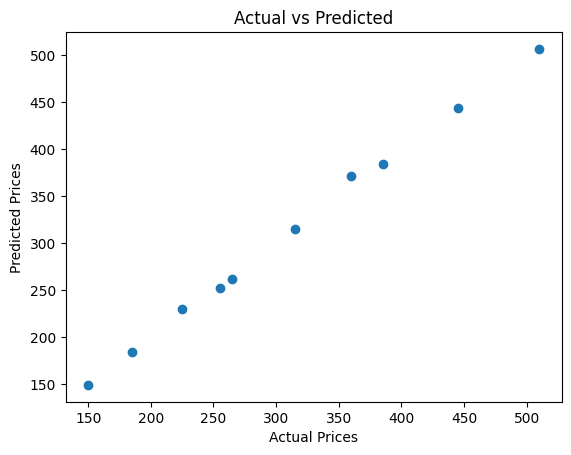

In [21]:


plt.scatter(y_train, y_pred_sgd)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted")
plt.show()

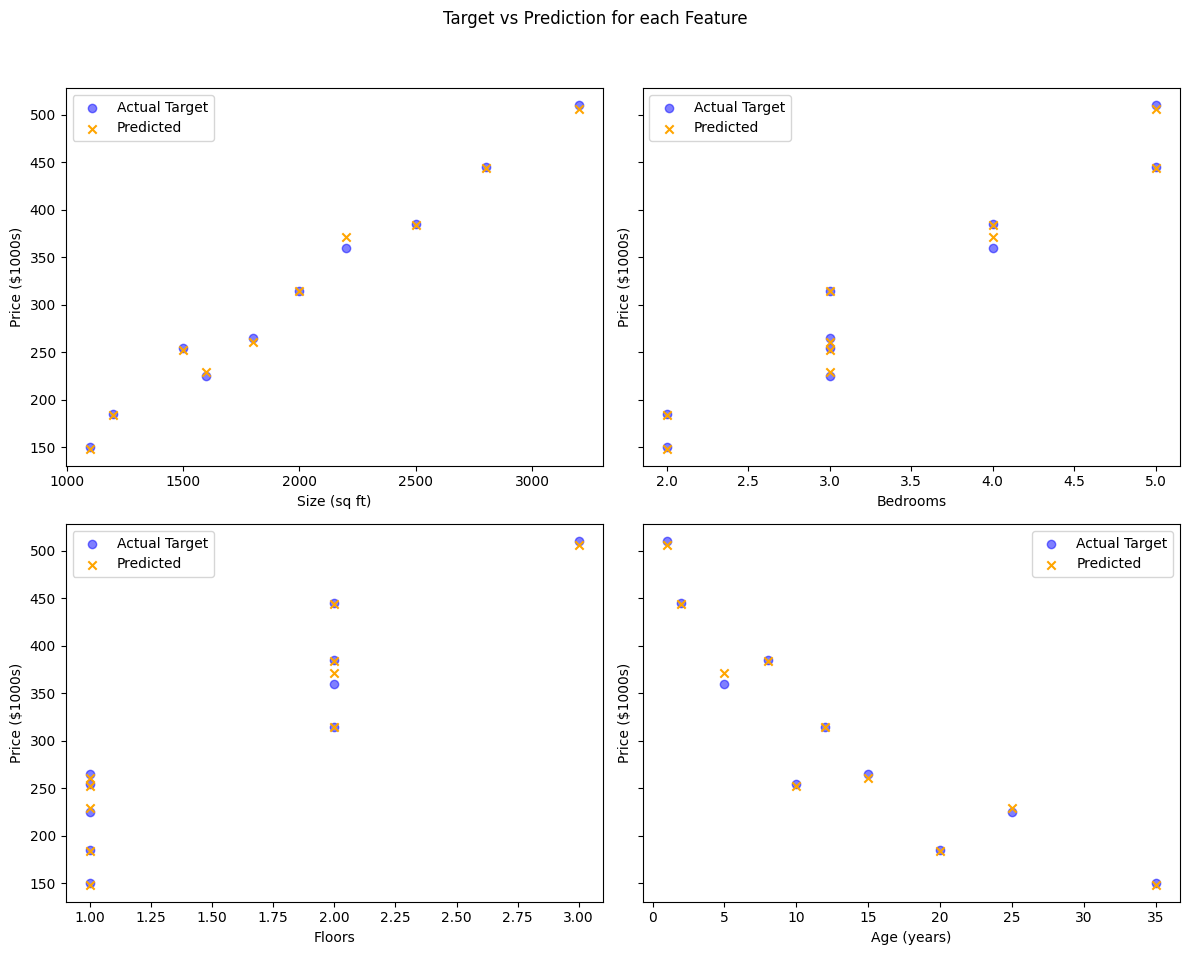

In [22]:


# Set up a figure with 2 rows and 2 columns
fig, ax = plt.subplots(2, 2, figsize=(12, 10), sharey=True)
fig.suptitle("Target vs Prediction for each Feature")

# Flatten the axes array for easy iteration
axes = ax.flatten()

for i in range(len(X_features)):
    # Plot the actual data points
    axes[i].scatter(X_train[:, i], y_train, label='Actual Target', color='blue', alpha=0.5)
    
    # Plot the predicted data points
    axes[i].scatter(X_train[:, i], y_pred_sgd, label='Predicted', color='orange', marker='x')
    
    axes[i].set_xlabel(X_features[i])
    axes[i].set_ylabel("Price ($1000s)")
    axes[i].legend()

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

# Mean Sqaured Error

Mean Squared Error: 17.75


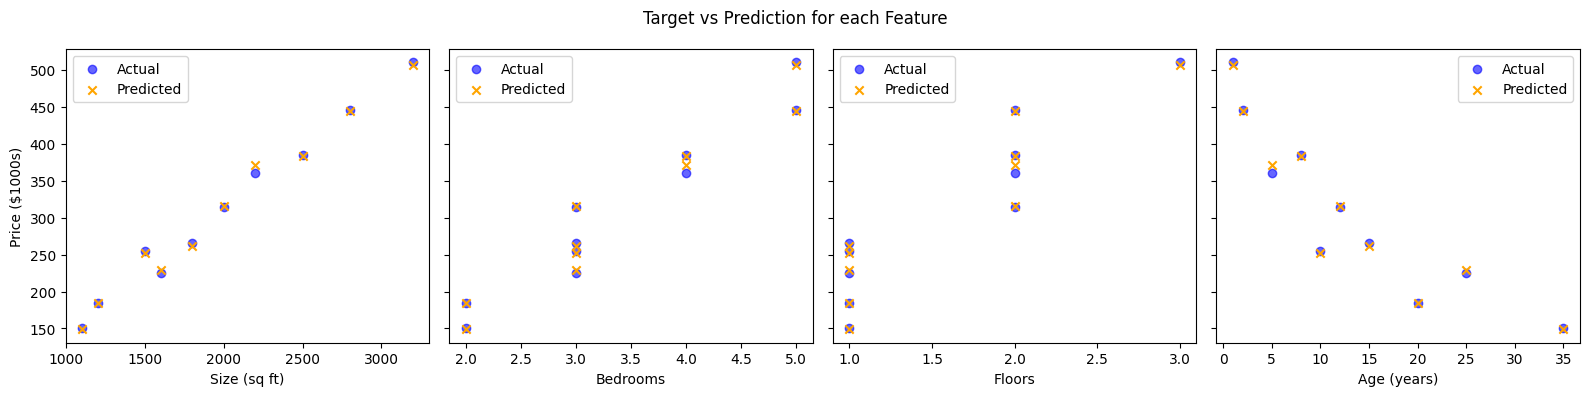

In [24]:


# 1. Calculate the Mean Squared Error
mse = mean_squared_error(y_train, y_pred_sgd)
print(f"Mean Squared Error: {mse:.2f}")

# 2. Visualise Target vs Predictions for each individual feature
fig, ax = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
fig.suptitle("Target vs Prediction for each Feature")

for i in range(len(X_features)):
    # Plot actual values
    ax[i].scatter(X_train[:, i], y_train, label='Actual', color='blue', alpha=0.6)
    
    # Plot predicted values
    ax[i].scatter(X_train[:, i], y_pred_sgd, label='Predicted', color='orange', marker='x')
    
    ax[i].set_xlabel(X_features[i])
    if i == 0:
        ax[i].set_ylabel("Price ($1000s)")
    ax[i].legend()

plt.tight_layout()
plt.show()

In [25]:
house_data=np.array([[1500,3,1,10]])
house_norm=scaler.transform(house_data)
prediction=sgdr.predict(house_norm)
print(prediction)

[252.15142298]
